# Dar_009 — P1 LCROSS calibrated spectral pilot
**D16:** two adjacent calibrated NSP1 **PREIMPACT** spectra and their labels, with the
official pixel-to-wavelength calibration table. Explore wavelength coverage, signal shape,
exposure-to-exposure changes and saturation metadata. There is no post-impact spectrum
in the selected pilot, so this is not a pre/post plume chemistry result.

In [1]:
from pathlib import Path
import sys, json, io, re, zipfile
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p/'outline.md').is_file() and (p/'notebooks').is_dir())
sys.path[:0] = [str(ROOT/'darrel stuff/EDA'),str(ROOT)]
DATA = ROOT/'darrel stuff/data'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from environment_workflow import LocalRun as Run, latest_completed_run
from notebooks.shared.inspection import verify_run, check_input
from research_p1_readers import (pilot_files, pin_source, read_pds4, pds4_chunks,
    pds4_definition, pds4_image, dose_profiles, pds3_number)
import research_p1_readers
def savefig(run, fig, name):
    fig.savefig(run.path(name+'.png'),dpi=140,bbox_inches='tight')
    display(fig); plt.close(fig)
def save_findings(run, findings):
    run.path('findings.json').write_text(json.dumps(findings,indent=2,default=str),encoding='utf-8')
    display(Markdown('**Executed findings**')); display(findings)
def pin(run, path): return pin_source(run, path)
def short(region): return region.split('_',2)[-1].replace('_',' ')

## Calibration controls
Use the actual nonlinear wavelength mapping, not a fabricated linspace from label bounds.
The science `Flux` is already calibrated radiance in W/(µm m² sr): do **not** apply the
DN/radiance calibration a second time. Keep negative/finite values rather than treating
all negatives as missing. Label saturation and mission phase remain explicit. Spectral
differences alone do not establish species, abundance or containment/exposure safety.

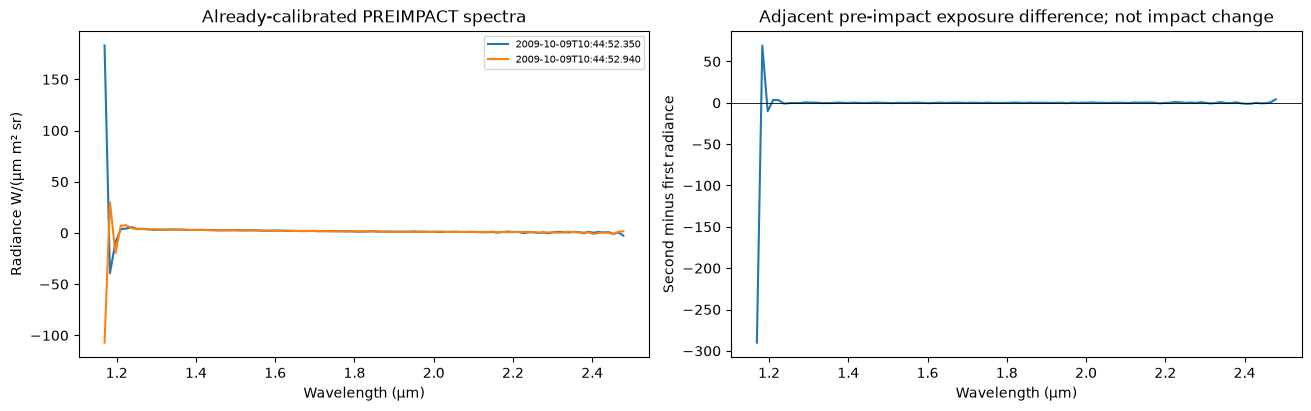

**Executed findings**

{'exposures': 2,
 'pixels_per_exposure': 100,
 'wavelength_range_um': [1.1693218, 2.4786203],
 'mission_phases': ['PREIMPACT'],
 'saturation_flags': ['N', 'N'],
 'holds': ['No post-impact comparison in selected products',
  'Species/abundance fitting not performed',
  'No sample containment/exposure measurements']}

Completed: C:\Darrel\Self-Projects\1 group proj\NASA-Space-Apps-Challenge-2026\darrel stuff\data\processed\analysis\dar_009_research_lcross\20261106T093355141497Z_8bb3c7


In [2]:
with Run(ROOT,'analysis/dar_009_research_lcross',{'datasets':['D16'],'scope':'two adjacent calibrated pre-impact exposures'},'Moon/Dar_009_research_lcross_spectra.ipynb') as run:
    run.input(Path(research_p1_readers.__file__))
    calibration=DATA/'moon/eda_support/D16/nsp1_cal.txt';pin(run,calibration);pin(run,calibration.with_suffix('.xml'))
    from research_p1_readers import nsp1_wavelengths
    mapping=nsp1_wavelengths(calibration)
    mapping.to_csv(run.path('source_pixel_wavelength_mapping.csv'),index=False)
    if len(mapping)!=100 or not np.array_equal(mapping.Pixel,np.arange(100)):raise ValueError('Unexpected NSP1 pixel/wavelength table')
    wavelength=mapping['Wavelength(um)'].to_numpy();spectra=[];metadata=[]
    for label in pilot_files(DATA,'D16','.xml'):
        tab=label.with_suffix('.tab');lbl=label.with_suffix('.lbl');pin(run,label);pin(run,tab);pin(run,lbl)
        f=read_pds4(label)
        if len(f)!=len(mapping):raise ValueError('Spectrum/calibration sample count mismatch')
        text=lbl.read_text(encoding='ascii')
        np.testing.assert_allclose(wavelength[[0,-1]], [pds3_number(text,'MINIMUM_SAMPLING_PARAMETER'),
            pds3_number(text,'MAXIMUM_SAMPLING_PARAMETER')], rtol=0,atol=1e-5)
        phase=re.search(r'MISSION_PHASE_NAME\s*=\s*"([^"\n]+)"',text)[1]
        saturation=re.search(r'LCROSS:SATURATION_FLAG\s*=\s*(\w+)',text)[1]
        timestamp=re.search(r'STOP_TIME\s*=\s*([^\s]+)',text)[1]
        f['pixel']=mapping.Pixel;f['wavelength_um']=wavelength;f['source_product']=label.stem
        spectra.append(f);metadata.append({'product':label.stem,'phase':phase,'saturation_flag':saturation,'stop_time':timestamp})
    if any(m['phase']!='PREIMPACT' for m in metadata):raise ValueError('Pilot scope changed; explicitly revise comparison')
    combined=pd.concat(spectra,ignore_index=True);combined.to_csv(run.path('calibrated_preimpact_spectra.csv'),index=False)
    pd.DataFrame(metadata).to_csv(run.path('exposure_metadata.csv'),index=False)
    a,b=spectra
    difference=pd.DataFrame({'wavelength_um':wavelength,'second_minus_first_radiance':b.Flux-a.Flux})
    difference.to_csv(run.path('adjacent_preimpact_difference.csv'),index=False)
    fig,axes=plt.subplots(1,2,figsize=(13,4),layout='constrained')
    for f,meta in zip(spectra,metadata):axes[0].plot(f.wavelength_um,f.Flux,label=meta['stop_time'])
    axes[0].set(title='Already-calibrated PREIMPACT spectra',xlabel='Wavelength (µm)',ylabel='Radiance W/(µm m² sr)');axes[0].legend(fontsize=7)
    axes[1].plot(wavelength,difference.second_minus_first_radiance);axes[1].axhline(0,color='black',lw=.6)
    axes[1].set(title='Adjacent pre-impact exposure difference; not impact change',xlabel='Wavelength (µm)',ylabel='Second minus first radiance')
    savefig(run,fig,'lcross_preimpact_spectra')
    save_findings(run,{'exposures':len(spectra),'pixels_per_exposure':len(mapping),'wavelength_range_um':[float(wavelength.min()),float(wavelength.max())],
        'mission_phases':sorted({m['phase'] for m in metadata}),'saturation_flags':[m['saturation_flag'] for m in metadata],
        'holds':['No post-impact comparison in selected products','Species/abundance fitting not performed','No sample containment/exposure measurements']})
OUT=run.directory;print('Completed:',OUT)

## Stage 3 role
This is calibrated spectral context and a tested wavelength reader for a later defined
sample-handling question. Add documented post-impact controls and species models before
chemical attribution. M09 direct containment/release tests remain missing; LCROSS does
not replace them or supply a Moon-wide toxicity map.